# EJERCICIO PRACTICO:
![logo itq](img/ITQimagen.png)


# Normalización y estandarización de datos médicos con CRISP-DM
**Dataset:** Diabetes 130-US Hospitals for Years 1999–2008 (UCI, id 296)
**Alcance:** Fases 1 y 2 de CRISP-DM completas; fase 3 hasta selección, limpieza y escalamiento (Min-Max y Z-score).
**Nota:** análisis académico; no se emiten diagnósticos ni se establecen relaciones causales.

**Autor:** bryan inga · **Fecha:** _9/11/2026_

link: <a href="">https://github.com/israelmena018-cmd/fundamentosDemachine67456387648.git</a>

## Paso 1. Descarga y registro de la fuente
Fuente: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

In [2]:
# Celda 1: instalar el paquete que descarga datasets de UCI (silencioso)
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Importar librerías del análisis
import sys, platform, datetime
from importlib.metadata import version      # para registrar versiones de las librerías
import numpy as np                          # cálculo numérico
import pandas as pd                         # manejo de tablas
import matplotlib                           # base de gráficos
import matplotlib.pyplot as plt             # interfaz de gráficos
import seaborn as sns                       # gráficos estadísticos
import sklearn                              # escaladores Min-Max y Z-score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from ucimlrepo import fetch_ucirepo         # descarga desde UCI

sns.set_theme(style="whitegrid")            # estilo uniforme de gráficos
pd.set_option("display.max_columns", 60)    # mostrar todas las columnas en tablas

In [4]:
# Celda 2: descargar el conjunto de datos desde UCI
dataset = fetch_ucirepo(id=296)

# Copia de todos los datos originales (esta copia NO se modifica)
df = dataset.data.original.copy()

# Verificar que cumple con el tamaño solicitado
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."

# Visualizar los primeros registros
display(df.head())

# Consultar el diccionario de variables oficial
display(dataset.variables)

# Guardar copia local original para desarrollar la actividad
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

C:\Users\ESTUDIANTE\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


In [5]:
# Registro de trazabilidad: fecha de descarga, dimensiones y versiones
registro = {
    "fecha_descarga": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
    "filas": df.shape[0],
    "columnas": df.shape[1],
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
    "ucimlrepo": version("ucimlrepo"),
}
pd.Series(registro, name="valor").to_frame()

,valor
fecha_descarga,2026-11-09 11:33
filas,101766
columnas,50
python,3.14.6
pandas,3.0.3
numpy,2.3.5
matplotlib,3.11.0
seaborn,0.13.2
scikit-learn,1.9.0
ucimlrepo,0.0.7


## Paso 2. Fase 1: Comprensión del negocio

**Problema.** Una readmisión hospitalaria ocurre cuando un paciente vuelve a ser hospitalizado poco después del alta. En diabetes, las readmisiones elevan costos y pueden reflejar problemas en el seguimiento o la transición de la atención.

**Actores interesados.** Equipo directivo y de calidad hospitalaria, personal médico y de enfermería, aseguradoras/pagadores, equipos de analítica de datos y los propios pacientes.

**Utilidad de explorar antes de modelar.** Permite conocer la calidad de los datos (faltantes, duplicados, atípicos), entender distribuciones y escalas, y evitar construir modelos sobre datos mal preparados.

**Objetivo general.** Comprender la calidad y la distribución de las características de las hospitalizaciones de pacientes con diabetes y preparar versiones comparables (normalizada y estandarizada) de sus variables cuantitativas.

**Preguntas de análisis**
1. ¿Cómo se distribuyen variables como el tiempo de hospitalización y el número de procedimientos de laboratorio, y qué escalas manejan?
2. ¿Cómo varían descriptivamente esas variables según la categoría de readmisión (`NO`, `<30`, `>30`)?
3. ¿Qué columnas presentan mayor proporción de datos faltantes y cómo deben tratarse?

**Criterios verificables de éxito**
- Se carga el dataset completo (> 100 000 filas) y se documentan dimensiones, hospitalizaciones y pacientes únicos.
- Existe diccionario de datos de todas las columnas y reporte de faltantes en número y porcentaje.
- Cada decisión de limpieza queda registrada con filas/columnas antes y después.
- Min-Max deja cada variable en [0, 1] y Z-score deja media ≈ 0 y desviación ≈ 1, comprobado por código.
- `readmitted` y los identificadores no se escalan.

**Variable de referencia.** `readmitted`: `NO` = sin readmisión; `<30` = readmitido en menos de 30 días; `>30` = readmitido después de 30 días. No se escala.

**Límites y consideraciones**
- **Periodo 1999–2008:** las prácticas clínicas, codificación y tratamientos pueden haber cambiado; los hallazgos no se generalizan a hoy.
- **Población:** hospitalizaciones de 130 hospitales de EE. UU.; no representa otros sistemas de salud (p. ej., Ecuador).
- **Varias hospitalizaciones por paciente:** una fila es una hospitalización, no un paciente; las filas de un mismo paciente no son independientes.
- **Confidencialidad:** los datos están anonimizados; no se intenta reidentificar personas.

## Paso 3. Fase 2: Comprensión de los datos
### 3.1 Dimensiones, hospitalizaciones y pacientes únicos

In [6]:
# Dimensiones reales del dataset cargado
print("Dimensiones (filas, columnas):", df.shape)

# Una fila = una hospitalización (encuentro)
print("Hospitalizaciones (filas):", len(df))
print("Encuentros únicos (encounter_id):", df["encounter_id"].nunique())

# Pacientes distintos: una persona puede aparecer en varias hospitalizaciones
print("Pacientes únicos (patient_nbr):", df["patient_nbr"].nunique())

# Pacientes con más de una hospitalización
hosp_por_paciente = df["patient_nbr"].value_counts()
print("Pacientes con >1 hospitalización:", (hosp_por_paciente > 1).sum())

Dimensiones (filas, columnas): (101766, 50)
Hospitalizaciones (filas): 101766
Encuentros únicos (encounter_id): 101766
Pacientes únicos (patient_nbr): 71518
Pacientes con >1 hospitalización: 16773


### 3.2 Diccionario de datos de todas las columnas

In [7]:
# Clasificación conceptual de las variables (un número almacenado no implica variable cuantitativa)
identificadores = ["encounter_id", "patient_nbr"]       # solo referencia, no se escalan
objetivo = "readmitted"                                  # variable de referencia, no se escala
codigos_cat = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]  # números que son categorías
numericas = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
             "number_outpatient", "number_emergency", "number_inpatient"]  # las 7 cuantitativas seleccionadas

def tipo_conceptual(c):
    # Devuelve el tipo conceptual según la lista a la que pertenece la columna
    if c in identificadores: return "Identificador"
    if c == objetivo: return "Categórica (objetivo)"
    if c in numericas: return "Cuantitativa discreta (conteo)"
    if c == "number_diagnoses": return "Cuantitativa discreta (no seleccionada)"
    if c in codigos_cat: return "Categórica (código numérico)"
    if c == "age": return "Categórica ordinal (rangos de edad)"
    return "Categórica"

def rol_analitico(c):
    # Rol de la columna dentro del análisis
    if c in identificadores: return "Identificador (excluir del escalamiento)"
    if c == objetivo: return "Variable de referencia (no escalar)"
    if c in numericas: return "Predictora cuantitativa (escalar)"
    if c == "number_diagnoses": return "Predictora cuantitativa (fuera del escalamiento)"
    return "Predictora categórica"

# Construir la tabla base con tipo observado, únicos y ejemplos
dic = pd.DataFrame({"columna": df.columns})
dic["tipo_observado"] = df.dtypes.astype(str).values
dic["n_unicos"] = df.nunique().values
dic["ejemplos"] = [", ".join(map(str, df[c].dropna().unique()[:4])) for c in df.columns]
dic["tipo_conceptual"] = dic["columna"].map(tipo_conceptual)
dic["rol_analitico"] = dic["columna"].map(rol_analitico)

# Agregar significado y unidades desde el diccionario oficial de UCI
meta = dataset.variables[["name", "description", "units"]].rename(
    columns={"name": "columna", "description": "significado", "units": "unidades_o_categorias"})
dic = dic.merge(meta, on="columna", how="left")
display(dic)

,columna,tipo_observado,n_unicos,ejemplos,tipo_conceptual,rol_analitico,significado,unidades_o_categorias
0,encounter_id,int64,101766,"2278392, 149190, 64410, 500364",Identificador,Identificador (excluir del escalamiento),Unique identifier of an encounter,None
1,patient_nbr,int64,71518,"8222157, 55629189, 86047875, 82442376",Identificador,Identificador (excluir del escalamiento),Unique identifier of a patient,None
2,race,str,5,"Caucasian, AfricanAmerican, Other, Asian",Categórica,Predictora categórica,"Values: Caucasian, Asian, African American, Hi...",None
3,gender,str,3,"Female, Male, Unknown/Invalid",Categórica,Predictora categórica,"Values: male, female, and unknown/invalid",None
4,age,str,10,"[0-10), [10-20), [20-30), [30-40)",Categórica ordinal (rangos de edad),Predictora categórica,"Grouped in 10-year intervals: [0, 10), [10, 20...",None
5,weight,str,9,"[75-100), [50-75), [0-25), [100-125)",Categórica,Predictora categórica,Weight in pounds.,None
6,admission_type_id,int64,8,"6, 1, 2, 3",Categórica (código numérico),Predictora categórica,Integer identifier corresponding to 9 distinct...,None
7,discharge_disposition_id,int64,26,"25, 1, 3, 6",Categórica (código numérico),Predictora categórica,Integer identifier corresponding to 29 distinc...,None
8,admission_source_id,int64,17,"1, 7, 2, 4",Categórica (código numérico),Predictora categórica,Integer identifier corresponding to 21 distinc...,None
9,time_in_hospital,int64,14,"1, 3, 2, 4",Cuantitativa discreta (conteo),Predictora cuantitativa (escalar),Integer number of days between admission and d...,None


### 3.3 Datos faltantes (nulos y marcadores `?` / `None`)

In [8]:
# Contar nulos reales, marcadores "?" y textos "None" por columna
faltantes = pd.DataFrame({
    "nulos_NaN": df.isna().sum(),
    "marcador_?": df.eq("?").sum(),
    "texto_None": df.eq("None").sum(),
})
faltantes["faltantes_(NaN+?)"] = faltantes["nulos_NaN"] + faltantes["marcador_?"]
faltantes["pct_faltantes"] = (faltantes["faltantes_(NaN+?)"] / len(df) * 100).round(2)

# Mostrar solo columnas con algún dato faltante o "None", de mayor a menor
display(faltantes[(faltantes["faltantes_(NaN+?)"] > 0) | (faltantes["texto_None"] > 0)]
        .sort_values("pct_faltantes", ascending=False))

,nulos_NaN,marcador_?,texto_None,faltantes_(NaN+?),pct_faltantes
weight,98569,0,0,98569,96.86
max_glu_serum,96420,0,0,96420,94.75
A1Cresult,84748,0,0,84748,83.28
medical_specialty,49949,0,0,49949,49.08
payer_code,40256,0,0,40256,39.56
race,2273,0,0,2273,2.23
diag_3,1423,0,0,1423,1.40
diag_2,358,0,0,358,0.35
diag_1,21,0,0,21,0.02


**Interpretación.** Revisa en la tabla: `weight` suele tener más del 90 % faltante; `payer_code` y `medical_specialty` también tienen alta proporción; `race` y los diagnósticos tienen pocos. En `max_glu_serum` y `A1Cresult`, la categoría `None` significa **prueba no realizada** (según la documentación), por lo que no es información ausente y se trata como categoría. _(Ajusta este texto a lo que observes en tu salida.)_

### 3.4 Duplicados e identificadores

In [9]:
# Filas completamente duplicadas
print("Filas duplicadas completas:", df.duplicated().sum())

# Identificadores de encuentro repetidos (deberían ser únicos)
print("encounter_id duplicados:", df["encounter_id"].duplicated().sum())

# patient_nbr repetido: puede ser válido (varias hospitalizaciones); NO se elimina
print("patient_nbr repetidos:", df["patient_nbr"].duplicated().sum(), "(hospitalizaciones válidas de un mismo paciente)")

Filas duplicadas completas: 0
encounter_id duplicados: 0
patient_nbr repetidos: 30248 (hospitalizaciones válidas de un mismo paciente)


### 3.5 Estadísticos descriptivos y frecuencias de `readmitted`

In [10]:
# Estadísticos: mínimo, máximo, media, mediana, desviación estándar y cuartiles
desc = df[numericas].agg(["min", "max", "mean", "median", "std"]).T          # resumen básico
desc["Q1"] = df[numericas].quantile(0.25)                                    # primer cuartil
desc["Q3"] = df[numericas].quantile(0.75)                                    # tercer cuartil
display(desc.round(2))

# Frecuencias absolutas y relativas de la variable de referencia
freq = df[objetivo].value_counts().to_frame("frecuencia")
freq["porcentaje"] = (freq["frecuencia"] / len(df) * 100).round(2)
display(freq)

,min,max,mean,median,std,Q1,Q3
time_in_hospital,1.0,14.0,4.40,4.0,2.99,2.0,6.0
num_lab_procedures,1.0,132.0,43.10,44.0,19.67,31.0,57.0
num_procedures,0.0,6.0,1.34,1.0,1.71,0.0,2.0
num_medications,1.0,81.0,16.02,15.0,8.13,10.0,20.0
number_outpatient,0.0,42.0,0.37,0.0,1.27,0.0,0.0
number_emergency,0.0,76.0,0.20,0.0,0.93,0.0,0.0
number_inpatient,0.0,21.0,0.64,0.0,1.26,0.0,1.0


,frecuencia,porcentaje
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


### 3.6 Visualizaciones (histogramas, diagramas de caja y frecuencias)

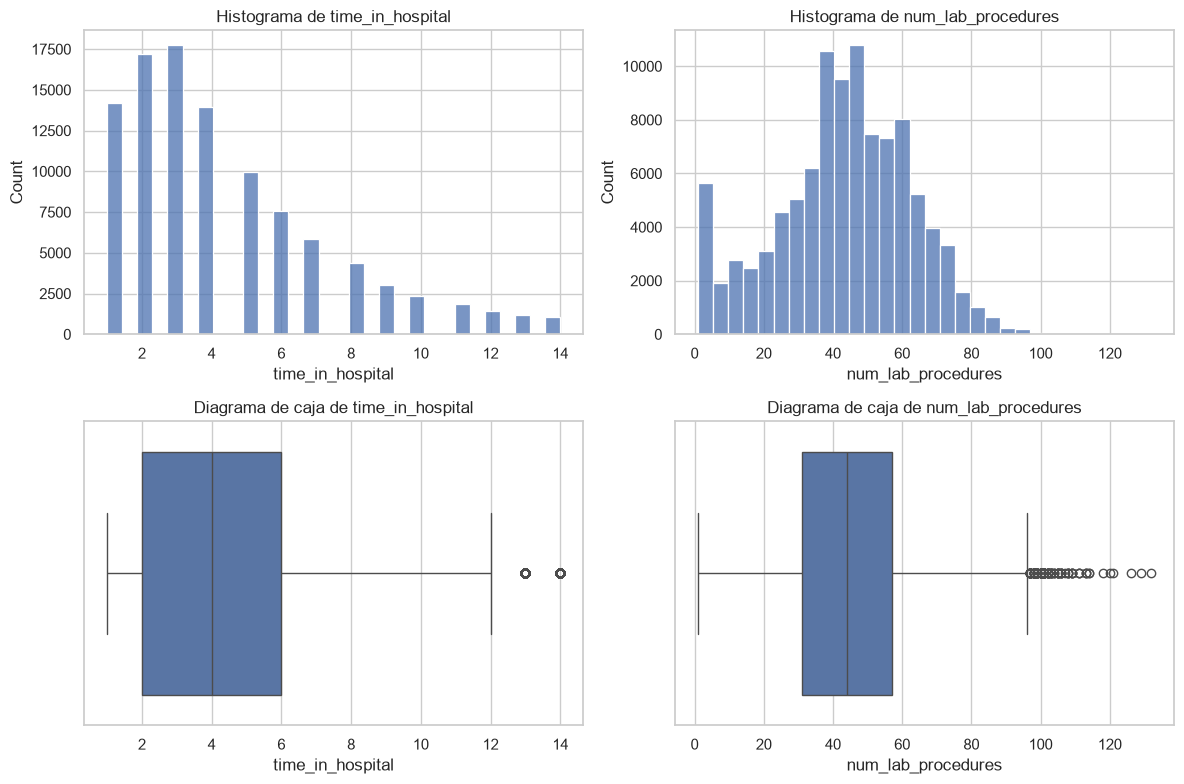

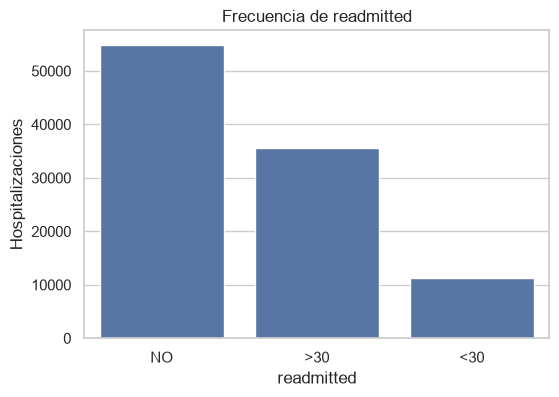

In [12]:
# Variables elegidas para los gráficos
vars_graf = ["time_in_hospital", "num_lab_procedures"]

# Histogramas y diagramas de caja (2 variables x 2 gráficos = 4 visualizaciones)
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for i, v in enumerate(vars_graf):
    sns.histplot(df[v], bins=30, ax=ejes[0, i])      # distribución de la variable
    ejes[0, i].set_title(f"Histograma de {v}")
    sns.boxplot(x=df[v], ax=ejes[1, i])              # mediana, cuartiles y atípicos
    ejes[1, i].set_title(f"Diagrama de caja de {v}")
plt.tight_layout()
plt.show()

# Gráfico de frecuencias de readmitted (quinta visualización)
plt.figure(figsize=(6, 4))
orden = ["NO", ">30", "<30"]
sns.countplot(x=df[objetivo], order=orden)
plt.title("Frecuencia de readmitted")
plt.ylabel("Hospitalizaciones")
plt.show()

**Interpretación (completar con tus resultados).**
- `time_in_hospital`: distribución asimétrica a la derecha; la mayoría de estancias es corta y hay pocas muy largas.
- `num_lab_procedures`: distribución más amplia con un pico en valores bajos y cola derecha; escala mucho mayor que la anterior.
- `readmitted`: la categoría `NO` es la más frecuente; `<30` es la minoritaria (clases desbalanceadas).

### 3.7 Valores atípicos con IQR

In [13]:
def resumen_iqr(serie):
    # Regla IQR: atípico si queda fuera de [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((serie < li) | (serie > ls)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "limite_inf": li, "limite_sup": ls,
                      "n_atipicos": n, "pct_atipicos": round(n / len(serie) * 100, 2)})

# Aplicar a todas las cuantitativas (se exige mínimo dos)
atipicos = pd.DataFrame({v: resumen_iqr(df[v]) for v in numericas}).T
display(atipicos)

,Q1,Q3,IQR,limite_inf,limite_sup,n_atipicos,pct_atipicos
time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252.0,2.21
num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,143.0,0.14
num_procedures,0.0,2.0,2.0,-3.0,5.0,4954.0,4.87
num_medications,10.0,20.0,10.0,-5.0,35.0,2557.0,2.51
number_outpatient,0.0,0.0,0.0,0.0,0.0,16739.0,16.45
number_emergency,0.0,0.0,0.0,0.0,0.0,11383.0,11.19
number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049.0,6.93


**Decisión sobre atípicos.** Los valores extremos (estancias largas, muchos procedimientos o medicamentos) son clínicamente posibles en pacientes complejos y representan información real, por lo que **se conservan** y no se eliminan solo por superar el umbral IQR. Se reconoce que Min-Max es sensible a ellos (comprimen el resto de valores) y que Z-score también los refleja en la media y desviación. Solo se excluiría un valor imposible (p. ej., negativo o fuera de rango lógico).

## Paso 4. Fase 3: Selección y limpieza
**Reglas explícitas**
1. Reemplazar el marcador `?` por `NaN`.
2. Eliminar columnas con más del 90 % de faltantes (no aportan información útil).
3. Variables categóricas con faltantes restantes: crear categoría `Desconocido` (se conserva la fila); `max_glu_serum` y `A1Cresult` sin dato = `No medido`.
4. Eliminar filas duplicadas completas (si existen). **No** eliminar `patient_nbr` repetidos.
5. Inconsistencias: eliminar filas con `gender = Unknown/Invalid` (muy pocas; sexo no válido).
6. Los identificadores se conservan como referencia pero se excluyen del escalamiento.
7. No se eliminan atípicos ni se duplican/inventan registros.

In [15]:
# Bitácora de decisiones con filas/columnas antes y después
bitacora = []
def registrar(regla, antes, despues):
    bitacora.append({"regla": regla, "filas_antes": antes[0], "cols_antes": antes[1],
                     "filas_despues": despues[0], "cols_despues": despues[1]})

df_clean = df.copy()                                   # trabajar sobre copia; df original intacto

# Regla 1: "?" -> NaN
antes = df_clean.shape
df_clean = df_clean.replace("?", np.nan)
registrar("1. '?' -> NaN", antes, df_clean.shape)

# Regla 2: en max_glu_serum y A1Cresult, "None" = prueba no realizada (NO es dato faltante)
antes = df_clean.shape
for c in ["max_glu_serum", "A1Cresult"]:
    df_clean[c] = df_clean[c].replace("None", np.nan).fillna("No medido")
registrar("2. max_glu_serum/A1Cresult: None -> 'No medido'", antes, df_clean.shape)

# Regla 3: eliminar columnas con >90% de faltantes (ahora solo debería caer weight)
pct = df_clean.isna().mean() * 100
cols_alto_faltante = pct[pct > 90].index.tolist()
print("Columnas eliminadas por >90% faltantes:", cols_alto_faltante)
antes = df_clean.shape
df_clean = df_clean.drop(columns=cols_alto_faltante)
registrar("3. Eliminar columnas >90% faltantes", antes, df_clean.shape)

# Regla 4: faltantes categóricos restantes -> "Desconocido" (se conserva la fila)
antes = df_clean.shape
cat_cols = [c for c in df_clean.select_dtypes(include="object").columns if c != objetivo]
df_clean[cat_cols] = df_clean[cat_cols].fillna("Desconocido")
registrar("4. Faltantes categóricos -> 'Desconocido'", antes, df_clean.shape)

# Regla 5: duplicados completos
antes = df_clean.shape
df_clean = df_clean.drop_duplicates()
registrar("5. Eliminar filas duplicadas completas", antes, df_clean.shape)

# Regla 6: inconsistencia en gender
print("Filas con gender inválido:", (df_clean["gender"] == "Unknown/Invalid").sum())
antes = df_clean.shape
df_clean = df_clean[df_clean["gender"] != "Unknown/Invalid"].copy()
registrar("6. Eliminar gender = Unknown/Invalid", antes, df_clean.shape)

# Verificar que el dataset de entrada sigue superando 100 000 filas
assert len(df_clean) > 100_000
display(pd.DataFrame(bitacora))

Columnas eliminadas por >90% faltantes: ['weight']
Filas con gender inválido: 3


C:\Users\ESTUDIANTE\AppData\Local\Temp\ipykernel_12524\1105991347.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df_clean.select_dtypes(include="object").columns if c != objetivo]


,regla,filas_antes,cols_antes,filas_despues,cols_despues
0,1. '?' -> NaN,101766,50,101766,50
1,2. max_glu_serum/A1Cresult: None -> 'No medido',101766,50,101766,50
2,3. Eliminar columnas >90% faltantes,101766,50,101766,49
3,4. Faltantes categóricos -> 'Desconocido',101766,49,101766,49
4,5. Eliminar filas duplicadas completas,101766,49,101766,49
5,6. Eliminar gender = Unknown/Invalid,101766,49,101763,49


In [23]:
# Asegurar tipo numérico en las variables cuantitativas (documentar cambio de tipos)
print("Tipos antes:\n", df_clean[numericas].dtypes.astype(str).value_counts())
df_clean[numericas] = df_clean[numericas].apply(pd.to_numeric, errors="raise")

# Copia de variables numéricas limpias ANTES de transformar
df_num_clean = df_clean[numericas].copy()
assert df_num_clean.isna().sum().sum() == 0, "Hay nulos en las numéricas"
df_clean.to_csv("hospitalizaciones_diabetes_limpio.csv", index=False)       # dataset limpio completo
df_num_clean.to_csv("variables_numericas_limpias.csv", index=False)         # solo numéricas limpias
print("Dataset limpio:", df_clean.shape, "| Numéricas limpias:", df_num_clean.shape)

Tipos antes:
 int64    7
Name: count, dtype: int64
Dataset limpio: (101763, 49) | Numéricas limpias: (101763, 7)


## Paso 5. Selección de variables cuantitativas
Se usan las **siete** variables indicadas. Se excluyen `encounter_id` y `patient_nbr` (identificadores); `admission_type_id`, `discharge_disposition_id` y `admission_source_id` (categorías codificadas con números); y `age`, que viene en intervalos y no es una edad numérica continua.

In [24]:
# Verificar significado, tipo y calidad de las siete variables seleccionadas
significado = {
    "time_in_hospital": "Duración de la hospitalización (días)",
    "num_lab_procedures": "Número de procedimientos de laboratorio",
    "num_procedures": "Número de procedimientos distintos de laboratorio",
    "num_medications": "Número de medicamentos distintos administrados",
    "number_outpatient": "Visitas ambulatorias durante el año anterior",
    "number_emergency": "Visitas de emergencia durante el año anterior",
    "number_inpatient": "Hospitalizaciones durante el año anterior",
}
sel = pd.DataFrame({
    "significado": pd.Series(significado),
    "tipo_en_df_limpio": df_num_clean.dtypes.astype(str),
    "nulos": df_num_clean.isna().sum(),
    "minimo": df_num_clean.min(),
    "maximo": df_num_clean.max(),
    "n_unicos": df_num_clean.nunique(),
})
display(sel)

# Comprobar que no se incluyó ninguna columna excluida
excluidas = identificadores + codigos_cat + ["age"]
assert not set(numericas) & set(excluidas), "Hay columnas excluidas dentro de las numéricas"
print("Columnas seleccionadas:", numericas)

# age viene en intervalos (categórica ordinal), no es edad continua
display(df_clean["age"].value_counts().sort_index().to_frame("hospitalizaciones"))

,significado,tipo_en_df_limpio,nulos,minimo,maximo,n_unicos
time_in_hospital,Duración de la hospitalización (días),int64,0,1,14,14
num_lab_procedures,Número de procedimientos de laboratorio,int64,0,1,132,118
num_procedures,Número de procedimientos distintos de laboratorio,int64,0,0,6,7
num_medications,Número de medicamentos distintos administrados,int64,0,1,81,75
number_outpatient,Visitas ambulatorias durante el año anterior,int64,0,0,42,39
number_emergency,Visitas de emergencia durante el año anterior,int64,0,0,76,33
number_inpatient,Hospitalizaciones durante el año anterior,int64,0,0,21,21


Columnas seleccionadas: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient']


,hospitalizaciones
age,
[0-10),161
[10-20),691
[20-30),1657
[30-40),3775
[40-50),9685
[50-60),17256
[60-70),22482
[70-80),26066
[80-90),17197


## Paso 6. Normalización Min-Max
Fórmula (variable no constante): $x_{norm} = \dfrac{x - x_{min}}{x_{max} - x_{min}}$, con rango [0, 1].
Se aplica `MinMaxScaler` sobre una **copia** de `df_num_clean`.

In [25]:
# Aplicar MinMaxScaler con rango [0, 1] sobre una copia de las siete variables limpias
escalador_mm = MinMaxScaler(feature_range=(0, 1))
df_minmax = pd.DataFrame(
    escalador_mm.fit_transform(df_num_clean.copy()),   # ajustar y transformar
    columns=df_num_clean.columns,                       # conservar nombres de columnas
    index=df_num_clean.index,                           # conservar correspondencia de filas
)

# Primeras diez filas transformadas
display(df_minmax.head(10))

# Tabla con mínimo y máximo antes y después
tabla_mm = pd.concat({
    "antes": df_num_clean.agg(["min", "max"]).T,
    "despues": df_minmax.agg(["min", "max"]).T,
}, axis=1)
display(tabla_mm)

# Columnas constantes (denominador cero): con rango 0 sklearn deja la escala en 1 y el resultado en 0
constantes = [c for c in numericas if df_num_clean[c].nunique() == 1]
print("Columnas constantes:", constantes if constantes else "ninguna")

# Comprobar el rango con tolerancia numérica (las no constantes deben ir de 0 a 1)
no_const = [c for c in numericas if c not in constantes]
assert np.allclose(df_minmax[no_const].min(), 0, atol=1e-9)
assert np.allclose(df_minmax[no_const].max(), 1, atol=1e-9)
print("Rango [0, 1] verificado en", len(no_const), "variables")

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000
9,0.846154,0.244275,0.500000,0.2125,0.000000,0.0,0.000000


antes      despues     
                     min  max     min  max
time_in_hospital       1   14     0.0  1.0
num_lab_procedures     1  132     0.0  1.0
num_procedures         0    6     0.0  1.0
num_medications        1   81     0.0  1.0
number_outpatient      0   42     0.0  1.0
number_emergency       0   76     0.0  1.0
number_inpatient       0   21     0.0  1.0

Columnas constantes: ninguna
Rango [0, 1] verificado en 7 variables


**Influencia de los valores extremos.** Min-Max depende del mínimo y del máximo; un solo valor extremo estira el rango y comprime todos los demás valores hacia cero (p. ej., si una variable tiene un máximo muy atípico, casi todos los datos quedan cerca de 0). **Columna constante:** si $x_{max} = x_{min}$ el denominador sería cero; `MinMaxScaler` lo maneja asignando escala 1 y devuelve 0 para toda la columna, evitando una división por cero. _(Redáctalo con tus palabras y cita un ejemplo de tu salida.)_

## Paso 7. Estandarización Z-score
Fórmula (variable no constante): $z = \dfrac{x - \mu}{\sigma}$, con $\mu$ y $\sigma$ de la variable usada para ajustar el escalador.
Se parte de **otra copia** de `df_num_clean` (no del resultado Min-Max).

In [26]:
# Aplicar StandardScaler sobre otra copia independiente de las variables limpias originales
escalador_z = StandardScaler()
df_zscore = pd.DataFrame(
    escalador_z.fit_transform(df_num_clean.copy()),
    columns=df_num_clean.columns,
    index=df_num_clean.index,
)

# Primeras diez filas transformadas
display(df_zscore.head(10))

# Media y desviación estándar (ddof=0 para concordar con StandardScaler)
verif_z = pd.DataFrame({"media": df_zscore.mean(), "desv_std_ddof0": df_zscore.std(ddof=0)})
display(verif_z.round(8))

# Comprobar con tolerancias: media ~0 y desviación ~1 (en columnas constantes la desviación es 0)
assert np.allclose(df_zscore[no_const].mean(), 0, atol=1e-8)
assert np.allclose(df_zscore[no_const].std(ddof=0), 1, atol=1e-8)
print("Media ~0 y desviación ~1 verificadas en", len(no_const), "variables")

# Rango observado: aparecen negativos y valores mayores que 1
display(df_zscore.agg(["min", "max"]).T)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,-1.137665,-0.106531,-0.785382,-1.848261,-0.291466,-0.212623,-0.503285
1,-0.467666,0.808376,-0.785382,0.243390,-0.291466,-0.212623,-0.503285
2,-0.802665,-1.631377,2.145823,-0.371802,1.286722,-0.212623,0.288561
3,-0.802665,0.045953,-0.199141,-0.002687,-0.291466,-0.212623,-0.503285
4,-1.137665,0.401751,-0.785382,-0.986993,-0.291466,-0.212623,-0.503285
5,-0.467666,-0.614813,2.732063,-0.002687,-0.291466,-0.212623,-0.503285
6,-0.132666,1.367486,-0.199141,0.612505,-0.291466,-0.212623,-0.503285
7,0.202334,1.519971,-0.785382,-0.494840,-0.291466,-0.212623,-0.503285
8,2.882331,1.265830,0.387100,1.473773,-0.291466,-0.212623,-0.503285
9,2.547331,-0.513157,0.973341,0.243390,-0.291466,-0.212623,-0.503285


,media,desv_std_ddof0
time_in_hospital,0.0,1.0
num_lab_procedures,-0.0,1.0
num_procedures,-0.0,1.0
num_medications,-0.0,1.0
number_outpatient,0.0,1.0
number_emergency,0.0,1.0
number_inpatient,0.0,1.0


Media ~0 y desviación ~1 verificadas en 7 variables


,min,max
time_in_hospital,-1.137665,3.217331
num_lab_procedures,-2.139659,4.518834
num_procedures,-0.785382,2.732063
num_medications,-1.848261,7.994805
number_outpatient,-0.291466,32.850487
number_emergency,-0.212623,81.465581
number_inpatient,-0.503285,16.125492


**Valores negativos y fuera de [0, 1].** Z-score centra los datos en la media: los valores menores que $\mu$ dan z negativo y los mayores dan z positivo. No acota a [0, 1]; un dato a 3 desviaciones de la media vale cerca de 3. Para columnas constantes, `StandardScaler` produce 0 y su desviación resultante es 0. _(Complétalo con valores mínimo/máximo de tu tabla.)_

**Nota sobre fuga de información.** Aquí los escaladores se ajustan sobre todos los datos porque la práctica es descriptiva. Si luego se entrenara un modelo, se separaría primero entrenamiento/prueba (evitando pacientes repetidos entre particiones), se ajustaría el escalador solo con entrenamiento y se aplicaría `transform` al resto.

## Paso 8. Comparación y exportación

In [27]:
# Tabla comparativa: mínimo, máximo, media y desviación (ddof=0) de las 7 variables en las 3 versiones
def estad(d):
    return pd.DataFrame({"min": d.min(), "max": d.max(), "media": d.mean(), "desv_std": d.std(ddof=0)})

comparacion = pd.concat({
    "original_limpio": estad(df_num_clean),
    "min_max": estad(df_minmax),
    "z_score": estad(df_zscore),
}, axis=1)
display(comparacion.round(3))
comparacion.round(6).to_csv("tabla_comparacion_estadistica.csv")   # entregable

original_limpio                       min_max              \
                               min  max   media desv_std     min  max  media   
time_in_hospital                 1   14   4.396    2.985     0.0  1.0  0.261   
num_lab_procedures               1  132  43.096   19.674     0.0  1.0  0.321   
num_procedures                   0    6   1.340    1.706     0.0  1.0  0.223   
num_medications                  1   81  16.022    8.128     0.0  1.0  0.188   
number_outpatient                0   42   0.369    1.267     0.0  1.0  0.009   
number_emergency                 0   76   0.198    0.930     0.0  1.0  0.003   
number_inpatient                 0   21   0.636    1.263     0.0  1.0  0.030   

                            z_score                         
                   desv_std     min     max media desv_std  
time_in_hospital      0.230  -1.138   3.217   0.0      1.0  
num_lab_procedures    0.150  -2.140   4.519  -0.0      1.0  
num_procedures        0.284  -0.785   2.732  -0.0      1.0  
num_medications       0.102  -1.848   7.995  -0.0      1.0  
number_outpatient     0.030  -0.291  32.850   0.0      1.0  
number_emergency      0.012  -0.213  81.466   0.0      1.0  
number_inpatient      0.060  -0.503  16.125   0.0      1.0

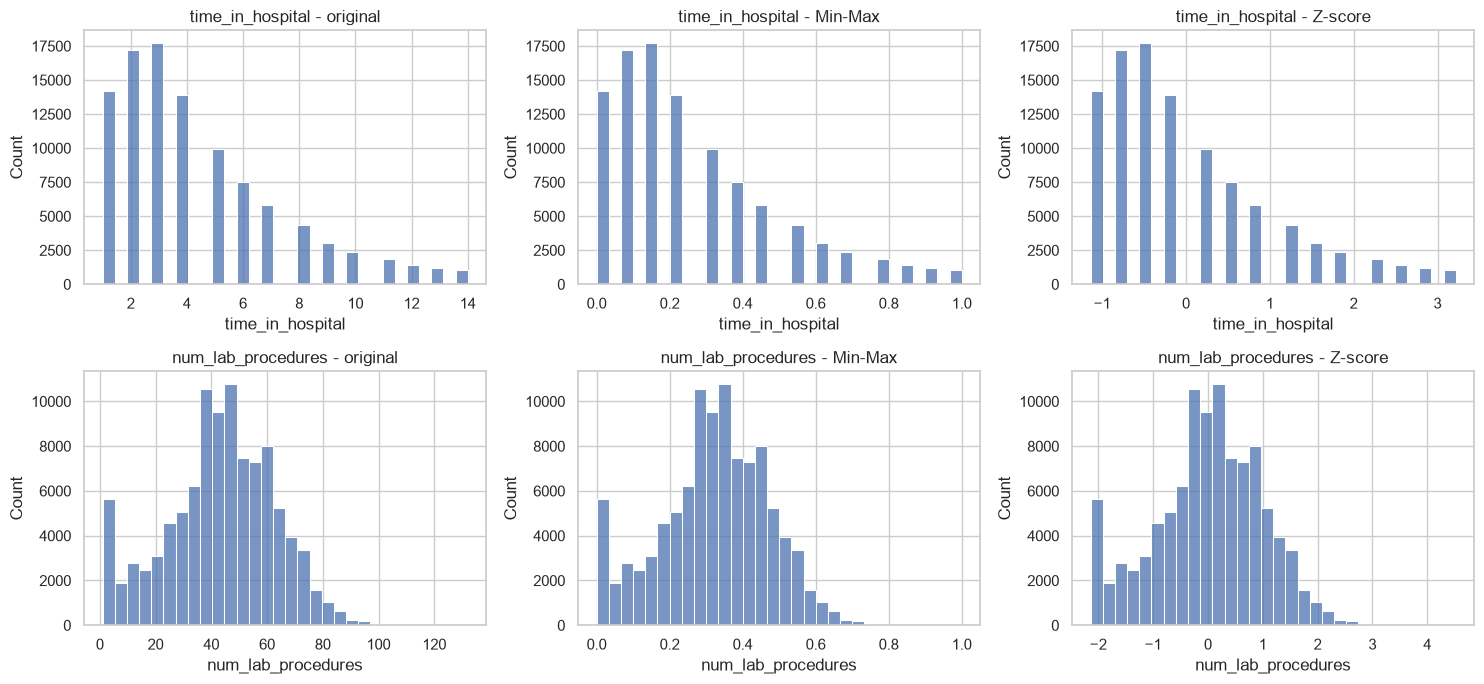

In [28]:
# Gráficos comparables de las tres versiones para dos variables
vars_comp = ["time_in_hospital", "num_lab_procedures"]
fig, ejes = plt.subplots(2, 3, figsize=(15, 7))
for i, v in enumerate(vars_comp):
    sns.histplot(df_num_clean[v], bins=30, ax=ejes[i, 0]); ejes[i, 0].set_title(f"{v} - original")
    sns.histplot(df_minmax[v], bins=30, ax=ejes[i, 1]);   ejes[i, 1].set_title(f"{v} - Min-Max")
    sns.histplot(df_zscore[v], bins=30, ax=ejes[i, 2]);   ejes[i, 2].set_title(f"{v} - Z-score")
plt.tight_layout()
plt.show()

**Interpretación (completar con tus gráficos).** La forma de la distribución (asimetría, moda, cola) se conserva porque ambas son transformaciones lineales ($ax + b$); lo que cambia es la escala del eje: Min-Max lo lleva a [0, 1] y Z-score lo centra en 0 con unidad de desviación.

In [29]:
# Demostración manual con cinco valores de una variable y contraste con Python
v = "time_in_hospital"
cinco = df_num_clean[v].head(5)                      # cinco valores (con su índice original)

# Parámetros usados (calculados con toda la columna, igual que los escaladores)
x_min, x_max = df_num_clean[v].min(), df_num_clean[v].max()
mu, sigma = df_num_clean[v].mean(), df_num_clean[v].std(ddof=0)
print(f"x_min={x_min}, x_max={x_max}, media={mu:.6f}, sigma(ddof=0)={sigma:.6f}")

# Cálculo manual de ambas transformaciones
manual_mm = (cinco - x_min) / (x_max - x_min)
manual_z = (cinco - mu) / sigma

demo = pd.DataFrame({
    "x": cinco,
    "minmax_manual": manual_mm, "minmax_python": df_minmax.loc[cinco.index, v],
    "z_manual": manual_z,       "z_python": df_zscore.loc[cinco.index, v],
})
display(demo.round(6))

# Contraste: manual y Python deben coincidir
assert np.allclose(demo["minmax_manual"], demo["minmax_python"])
assert np.allclose(demo["z_manual"], demo["z_python"])
print("Cálculo manual = salida de Python")

x_min=1, x_max=14, media=4.396018, sigma(ddof=0)=2.985078


,x,minmax_manual,minmax_python,z_manual,z_python
0,1,0.000000,0.000000,-1.137665,-1.137665
1,3,0.153846,0.153846,-0.467666,-0.467666
2,2,0.076923,0.076923,-0.802665,-0.802665
3,2,0.076923,0.076923,-0.802665,-0.802665
4,1,0.000000,0.000000,-1.137665,-1.137665


Cálculo manual = salida de Python


In [30]:
# Comprobaciones finales de filas, nulos e índice (evidencia de reproducibilidad)
assert df_minmax.shape == df_zscore.shape == df_num_clean.shape
assert (df_minmax.index == df_zscore.index).all() and (df_minmax.index == df_num_clean.index).all()
assert df_minmax.isna().sum().sum() == 0 and df_zscore.isna().sum().sum() == 0
assert list(df_minmax.columns) == list(df_zscore.columns) == numericas

# Exportar las siete variables conservando orden e índice de referencia (índice original del df)
df_minmax.to_csv("datos_normalizados.csv", index=True, index_label="indice_original")
df_zscore.to_csv("datos_estandarizados.csv", index=True, index_label="indice_original")

# Correspondencia con los registros originales: indice_original -> identificadores
correspondencia = df_clean.loc[df_minmax.index, identificadores].reset_index(names="indice_original")
correspondencia.to_csv("correspondencia_registros.csv", index=False)

# Comprobar que el índice apunta a las mismas filas del dataset original
assert (df.loc[df_minmax.index, "encounter_id"].values == correspondencia["encounter_id"].values).all()
print("Exportados:", df_minmax.shape, "filas/columnas. Correspondencia verificada.")

Exportados: (101763, 7) filas/columnas. Correspondencia verificada.


## Preguntas de reflexión
_(Respuestas base; reescríbelas con tus propias palabras.)_

1. **¿Por qué un código categórico numérico no debe escalarse como una medición?** Porque los números solo identifican categorías (p. ej., tipo de admisión 1, 2, 3); no tienen orden ni distancia con sentido. Escalarlos implicaría que "3" es el triple de "1", lo cual es falso.
2. **¿Cómo afectaría un valor extremo a Min-Max y a Z-score?** En Min-Max cambia el máximo o mínimo y comprime al resto de valores en un rango pequeño. En Z-score aumenta la media y sobre todo la desviación, reduciendo la magnitud de los demás z; el propio extremo sigue lejos (valor z alto).
3. **¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?** Cada fila es una hospitalización con su `encounter_id`; el mismo `patient_nbr` puede ser internado varias veces y cada ingreso tiene sus propios datos (fechas, medicamentos, resultado). Un duplicado sería una fila idéntica en todas sus columnas.
4. **¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?** Cambiar de escala es una transformación lineal: no altera la forma ni la asimetría. Corregir la asimetría requiere transformaciones no lineales (logaritmo, raíz, Box-Cox).
5. **¿Cómo evitaría la fuga de información al entrenar un modelo?** Dividiendo primero en entrenamiento y prueba (sin compartir pacientes entre particiones), ajustando el escalador solo con entrenamiento y aplicando `transform` con esos parámetros a los demás subconjuntos (idealmente dentro de un `Pipeline`).

## Conclusiones
- **Preguntas de análisis.** (1) Las variables cuantitativas tienen escalas muy distintas y distribuciones asimétricas a la derecha; (2) la comparación por categoría de `readmitted` es descriptiva y no implica causalidad; (3) `weight`, `payer_code` y `medical_specialty` concentran los faltantes y se trataron con reglas explícitas. _(Ajusta con tus resultados.)_
- **Cuándo usar cada transformación.** Min-Max cuando se requiere un rango fijo [0, 1] (p. ej., redes neuronales, distancias) y no hay extremos dominantes. Z-score cuando se comparan variables en unidades de desviación o los algoritmos asumen datos centrados (regresión regularizada, SVM, PCA) y es más estable ante extremos moderados.
- **Reproducibilidad.** Se registraron versiones, fecha de descarga, bitácora de limpieza y comprobaciones por código; se exportaron `datos_normalizados.csv` y `datos_estandarizados.csv` con el mismo índice de referencia.
- **Limitaciones.** Periodo 1999–2008, hospitales de EE. UU., hospitalizaciones repetidas por paciente, escaladores ajustados sobre todos los datos, atípicos conservados; análisis académico, sin diagnóstico ni causalidad.

## Fuente y asistencia externa
Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999–2008* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

scikit-learn. (s. f.). *MinMaxScaler* y *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html